In [2]:
import kagglehub
import pandas as pd
import os

# Download the vehicle dataset from Kaggle
path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")
print("Dataset path:", path)

# Find and load the CSV file from the downloaded folder
files = os.listdir(path)
print("Files:", files)

# Load the main car data csv file
df = pd.read_csv(os.path.join(path, 'car data.csv'))
print("Successfully loaded! Shape:", df.shape)
display(df.head())

100%|████████████████████████████████████████████████████████████████████████████████| 292k/292k [00:00<00:00, 451kB/s]

Extracting files...


Dataset path: C:\Users\Steven\.cache\kagglehub\datasets\nehalbirla\vehicle-dataset-from-cardekho\versions\4
Files: ['car data.csv', 'CAR DETAILS FROM CAR DEKHO.csv', 'Car details v3.csv', 'car details v4.csv']
Successfully loaded! Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
import datetime

# 1. Calculate car age (Current Year minus manufacturing year)
current_year = datetime.datetime.now().year
df['Car_Age'] = current_year - df['Year']

# 2. Extract brand from the car name column (assuming brand is the first word)
# Check what your car name column is called (e.g., 'Car_Name' or 'name')
car_name_col = 'Car_Name' if 'Car_Name' in df.columns else 'name'
df['Brand'] = df[car_name_col].apply(lambda x: str(x).split()[0].title())

print("--- Feature Engineering Complete ---")
print(df[['Year', 'Car_Age', car_name_col, 'Brand']].head())

--- Feature Engineering Complete ---
   Year  Car_Age Car_Name  Brand
0  2014       12     ritz   Ritz
1  2013       13      sx4    Sx4
2  2017        9     ciaz   Ciaz
3  2011       15  wagon r  Wagon
4  2014       12    swift  Swift


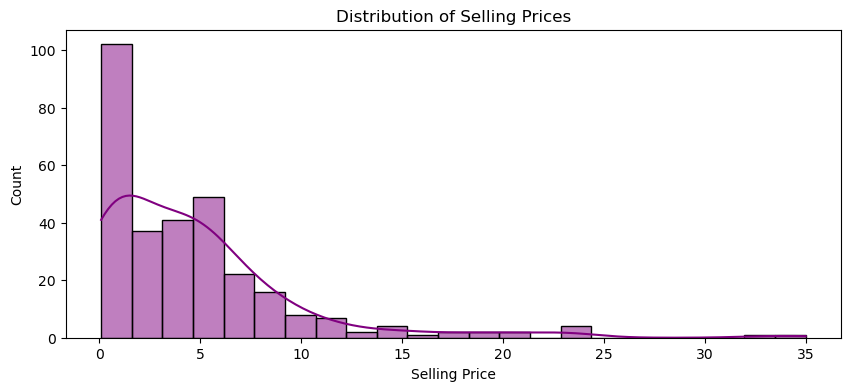

C:\Users\Steven\AppData\Local\Temp\ipykernel_10376\1227582468.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=fuel_col, y='Selling_Price', data=df, palette='Set2')


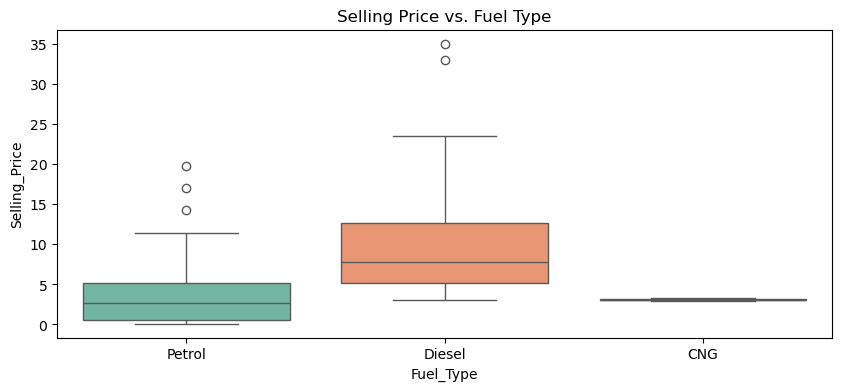

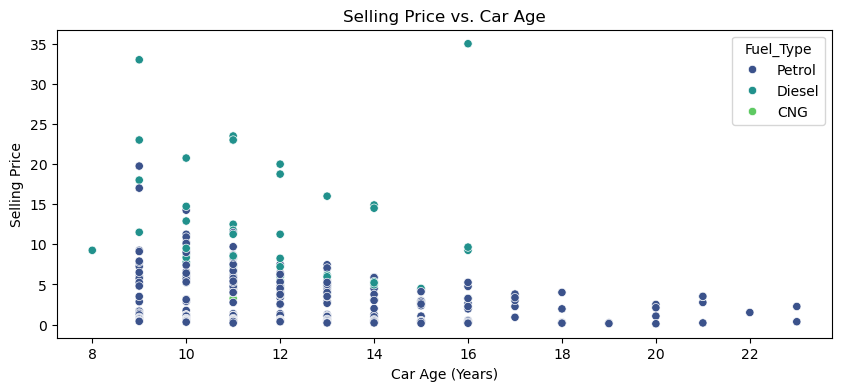

In [4]:
# 1. Distribution of Selling Prices
plt.figure(figsize=(10, 4))
sns.histplot(df['Selling_Price'], kde=True, color='purple')
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price")
plt.show()

# 2. Price vs. Fuel Type Box Plot (Check column name e.g., 'Fuel_Type')
fuel_col = 'Fuel_Type' if 'Fuel_Type' in df.columns else 'fuel'
plt.figure(figsize=(10, 4))
sns.boxplot(x=fuel_col, y='Selling_Price', data=df, palette='Set2')
plt.title("Selling Price vs. Fuel Type")
plt.show()

# 3. Price vs. Car Age Scatter Plot
plt.figure(figsize=(10, 4))
sns.scatterplot(x='Car_Age', y='Selling_Price', data=df, hue=fuel_col, palette='viridis')
plt.title("Selling Price vs. Car Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.show()

In [5]:
# Select categorical columns to encode (e.g., Fuel_Type, Seller_Type, Transmission, Brand)
categorical_features = [col for col in ['Fuel_Type', 'Seller_Type', 'Transmission', 'Brand'] if col in df.columns]

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True)

print("Encoded Data Shape:", df_encoded.shape)

Encoded Data Shape: (301, 54)


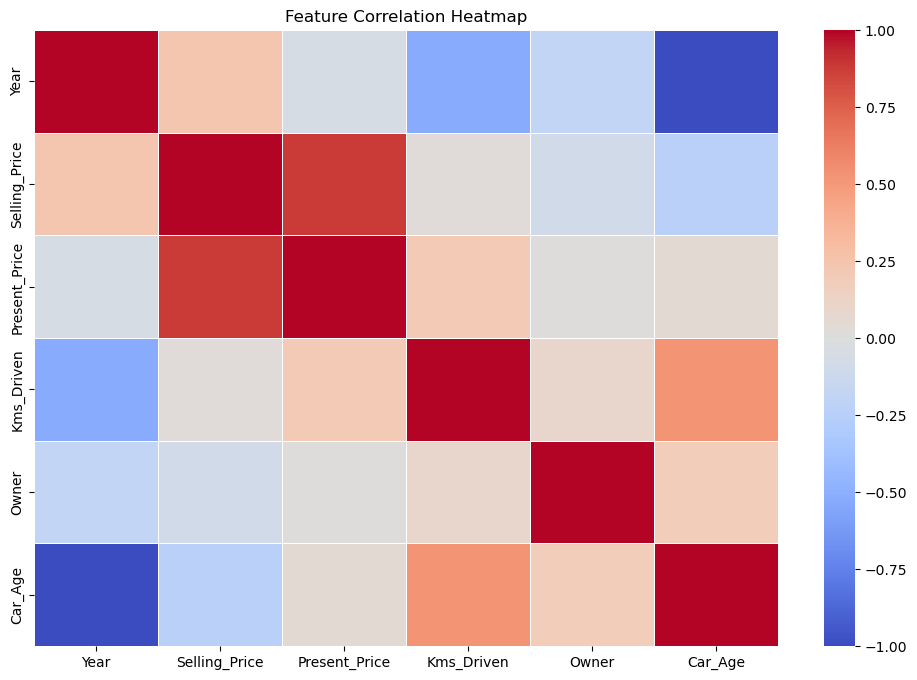

In [6]:
plt.figure(figsize=(12, 8))
numeric_df = df_encoded.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

# Drop non-feature columns like original car name or year if redundant
drop_cols = [car_name_col, 'Year', 'Selling_Price']
X = df_encoded.drop(columns=[col for col in drop_cols if col in df_encoded.columns])
y = df_encoded['Selling_Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")

Training set: (240, 51)
Testing set: (61, 51)


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42)
}

model_results = {}

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    # Predict
    y_pred = model.predict(X_test)
    
    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    model_results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    
    print(f"--- {name} ---")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}\n")

--- Linear Regression ---
MAE:  1.2184
RMSE: 1.8597
R²:   0.8499

--- Random Forest Regressor ---
MAE:  0.6059
RMSE: 0.8734
R²:   0.9669

--- Gradient Boosting Regressor ---
MAE:  0.5572
RMSE: 0.8719
R²:   0.9670



C:\Users\Steven\AppData\Local\Temp\ipykernel_10376\1597131713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='magma')


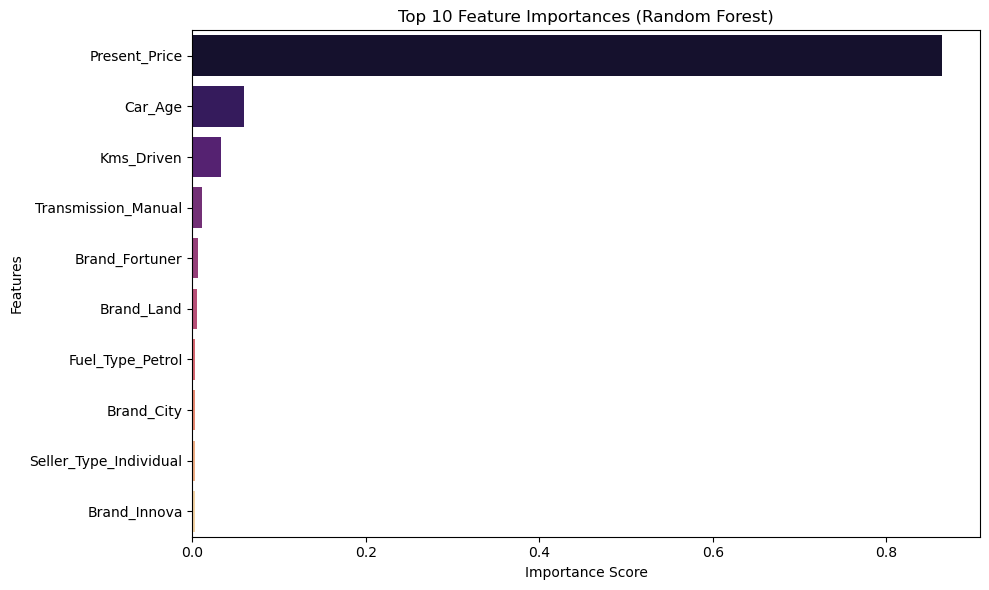

In [9]:
# Assuming Random Forest or Gradient Boosting is the best model
best_model = models["Random Forest Regressor"]

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='magma')
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()